# 02 · EDA básico — Competencia crediticia

Versión **paso a paso** del análisis exploratorio. Cada sección responde una
pregunta sencilla y explica qué se está viendo. Para un análisis más
avanzado consulta `01_eda.ipynb`.

**Objetivo del modelo:** predecir la probabilidad de que un cliente tenga
morosidad grave (90 días o más de atraso) en los próximos 2 años.
**Métrica:** AUC-ROC.

**Qué se podrá experimentar en la competencia** (y dónde ayuda este EDA):

| Tema | Qué nos dice este EDA |
| --- | --- |
| Calidad de datos (duplicados) | Sección 1 |
| Valores faltantes y atípicos | Secciones 5, 7 y 10 |
| Ingeniería y selección de variables | Secciones 8 y 9 |
| Escalado y preparación de variables | Sección 10 |
| Algoritmos de clasificación | Sección 11 (desbalance) |
| Regularización, validación cruzada, hiperparámetros | Sección 11 |

## 0. Preparación
Cargamos las librerías y los datos. Los archivos viven en `data/raw/`
(se descargan con `PYTHONPATH=src uv run python -m etl.download`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
train = pd.read_csv(ROOT / "data/raw/train.csv")
test = pd.read_csv(ROOT / "data/raw/test.csv")

TARGET = "SeriousDlqin2yrs"
ID = "Id"
FEATS = [c for c in train.columns if c not in (TARGET, ID)]

## 1. Ordenamiento y registros duplicados
Antes de explorar, revisamos la **calidad básica** del dataset: ¿hay
registros repetidos?

**Criterio de eliminación:** solo se elimina una fila si su `Id` está
repetido (el mismo registro cargado dos veces). Las filas con `Id` distinto se
conservan aunque su contenido sea idéntico, porque pueden ser clientes
distintos con el mismo perfil; esas solo se **reportan**.

Primero ordenamos los datos:
- Por `Id`, para tener un orden estable y reproducible.
- Por todas las variables, para que los registros iguales queden juntos y se
  puedan revisar a simple vista.

In [2]:
train = train.sort_values(ID).reset_index(drop=True)
test = test.sort_values(ID).reset_index(drop=True)

# Orden por todas las columnas: los registros idénticos quedan contiguos
train_ordenado = train.sort_values(FEATS + [TARGET], na_position="last")
train_ordenado.head()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
94080,134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
95976,137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
32028,45616,0,0.0,21,0,0.0,1.0,1,0,0,0,0.0
85812,122511,0,0.0,21,0,0.0,1.0,2,0,0,0,0.0
45297,64512,0,0.0,21,0,0.0,240.0,1,0,0,0,0.0


Revisamos tres tipos de duplicado:

| Tipo | Definición | Acción |
| --- | --- | --- |
| Por `Id` | El mismo `Id` aparece más de una vez | **Se elimina** la copia |
| Mismo contenido | Mismas variables y mismo objetivo, distinto `Id` | Se reporta, se conserva |
| En conflicto | Mismas variables pero objetivo distinto | Se reporta, se conserva |

In [3]:
dup_id = train[ID].duplicated()
dup_exacto = train.duplicated(subset=FEATS + [TARGET], keep="first")
dup_variables = train.duplicated(subset=FEATS, keep=False)
grupos_conflicto = (
    train[dup_variables]
    .groupby(FEATS, dropna=False)[TARGET]
    .nunique()
    .gt(1)
    .sum()
)

resumen_dup = pd.DataFrame(
    {
        "registros": [
            dup_id.sum(),
            dup_exacto.sum(),
            train.duplicated(subset=FEATS + [TARGET], keep=False).sum(),
            grupos_conflicto,
        ]
    },
    index=[
        "Id repetidos",
        "Mismo contenido con distinto Id (copias)",
        "Filas involucradas en contenido repetido",
        "Grupos en conflicto (mismo perfil, objetivo distinto)",
    ],
)
resumen_dup

,registros
Id repetidos,0
Mismo contenido con distinto Id (copias),339
Filas involucradas en contenido repetido,562
"Grupos en conflicto (mismo perfil, objetivo distinto)",26


### Notificación

In [4]:
n_dup_id = int(dup_id.sum())
n_dup_contenido = int(dup_exacto.sum())
if n_dup_id > 0:
    print(f"⚠️ Hay {n_dup_id:,} Id repetidos: se eliminarán las copias.")
else:
    print("✅ No hay Id repetidos: no se elimina ninguna fila.")

if n_dup_contenido > 0:
    pct = n_dup_contenido / len(train) * 100
    print(
        f"ℹ️ Hay {n_dup_contenido:,} registros con el mismo contenido y distinto Id "
        f"({pct:.2f} % de train). Se conservan porque su Id no se repite."
    )

if grupos_conflicto > 0:
    print(
        f"ℹ️ {grupos_conflicto} grupos tienen el mismo perfil con objetivo distinto. "
        "No se eliminan (ambos resultados son reales), pero son ruido para el modelo."
    )

✅ No hay Id repetidos: no se elimina ninguna fila.
ℹ️ Hay 339 registros con el mismo contenido y distinto Id (0.32 % de train). Se conservan porque su Id no se repite.
ℹ️ 26 grupos tienen el mismo perfil con objetivo distinto. No se eliminan (ambos resultados son reales), pero son ruido para el modelo.


In [5]:
# Ejemplos: registros duplicados vistos juntos gracias al ordenamiento
mascara = train_ordenado.duplicated(subset=FEATS + [TARGET], keep=False)
train_ordenado[mascara].head(10)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
94080,134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
95976,137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
18011,25633,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
58645,83553,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
30887,44007,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
38319,54654,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
18901,26907,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
62910,89634,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
79224,113076,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
82871,118284,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0


In [6]:
# ¿Cómo son los duplicados frente al total?
filas_dup = train.duplicated(subset=FEATS + [TARGET], keep=False)
pd.DataFrame(
    {
        "duplicados": [
            train.loc[filas_dup, TARGET].mean(),
            train.loc[filas_dup, "MonthlyIncome"].isna().mean(),
            train.loc[filas_dup, "age"].median(),
        ],
        "todo train": [
            train[TARGET].mean(),
            train["MonthlyIncome"].isna().mean(),
            train["age"].median(),
        ],
    },
    index=["tasa de morosidad", "proporción sin ingreso", "edad mediana"],
).round(3)

,duplicados,todo train
tasa de morosidad,0.037,0.067
proporción sin ingreso,0.854,0.198
edad mediana,49.500,52.000


**Lectura:** los duplicados son, en su mayoría, perfiles "delgados": sin
ingreso reportado y con casi todas las variables en cero. Es posible que
algunos sean personas distintas con el mismo perfil, pero como tienen
exactamente la misma información y el mismo resultado, en el modelado pesan
doble. Como su `Id` es distinto, **se conservan**. Si más adelante se quiere
probar su efecto, se puede comparar el AUC con y sin ellos en la validación
cruzada.

### Limpieza y cifras de control
Eliminamos solo las filas con `Id` repetido (se conserva la primera) y
verificamos con cifras de control que se quitó exactamente lo esperado.

In [7]:
filas_antes = len(train)
tasa_antes = train[TARGET].mean()

train = train.drop_duplicates(subset=ID, keep="first").reset_index(drop=True)

filas_despues = len(train)
tasa_despues = train[TARGET].mean()
cifras_control = pd.DataFrame(
    {
        "filas": [filas_antes, filas_despues, filas_despues - filas_antes],
        "tasa de morosidad": [tasa_antes, tasa_despues, tasa_despues - tasa_antes],
    },
    index=["antes", "después", "diferencia"],
)
display(cifras_control.style.format({"tasa de morosidad": "{:.4f}"}))

# Reglas de calidad (DQ): si alguna falla, el notebook se detiene
assert filas_antes - filas_despues == n_dup_id, "Se eliminaron filas de más o de menos"
assert train[ID].is_unique, "Quedan Id repetidos"
print(f"✅ Dataset listo: {filas_despues:,} filas ({filas_antes - filas_despues} eliminadas).")

,filas,tasa de morosidad
antes,105000,0.0668
después,105000,0.0668
diferencia,0,0.0000


✅ Dataset listo: 105,000 filas (0 eliminadas).


### ¿Y en `test`?

In [8]:
n_dup_test = int(test.duplicated(subset=FEATS).sum())
print(f"Registros de test con perfil repetido: {n_dup_test}")
print("ℹ️ En test NO se elimina nada: la competencia pide una predicción por cada Id.")

Registros de test con perfil repetido: 80
ℹ️ En test NO se elimina nada: la competencia pide una predicción por cada Id.


**A partir de aquí, todo el análisis usa `train` sin `Id` repetidos.**

## 2. Diccionario de variables
Qué significa cada columna. Es la base para interpretar todo lo demás.

In [9]:
DICCIONARIO = {
    "SeriousDlqin2yrs": "OBJETIVO. 1 = morosidad grave (90+ días) en 2 años; 0 = no.",
    "RevolvingUtilizationOfUnsecuredLines": "Saldo en tarjetas y líneas de crédito / límite total. Debería estar entre 0 y 1.",
    "age": "Edad del cliente en años.",
    "NumberOfTime30-59DaysPastDueNotWorse": "Veces con atraso de 30 a 59 días (sin llegar a peor).",
    "DebtRatio": (
        "Pagos MENSUALES de deuda, pensión alimenticia y vivienda / ingreso "
        "MENSUAL bruto. Ojo: si falta el ingreso, guarda el monto mensual de deuda."
    ),
    "MonthlyIncome": (
        "Ingreso MENSUAL bruto en dólares (USD). No es diario ni quincenal: "
        "mediana 5,400 al mes ≈ 64,800 al año."
    ),
    "NumberOfOpenCreditLinesAndLoans": "Número de créditos y líneas abiertas.",
    "NumberOfTimes90DaysLate": "Veces con atraso de 90 días o más.",
    "NumberRealEstateLoansOrLines": "Número de créditos hipotecarios o inmobiliarios.",
    "NumberOfTime60-89DaysPastDueNotWorse": "Veces con atraso de 60 a 89 días (sin llegar a peor).",
    "NumberOfDependents": "Número de dependientes económicos (sin contar al cliente).",
}
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(DICCIONARIO, name="descripción").to_frame())

,descripción
SeriousDlqin2yrs,OBJETIVO. 1 = morosidad grave (90+ días) en 2 años; 0 = no.
RevolvingUtilizationOfUnsecuredLines,Saldo en tarjetas y líneas de crédito / límite total. Debería estar entre 0 y 1.
age,Edad del cliente en años.
NumberOfTime30-59DaysPastDueNotWorse,Veces con atraso de 30 a 59 días (sin llegar a peor).
DebtRatio,"Pagos MENSUALES de deuda, pensión alimenticia y vivienda / ingreso MENSUAL bruto. Ojo: si falta el ingreso, guarda el monto mensual de deuda."
MonthlyIncome,"Ingreso MENSUAL bruto en dólares (USD). No es diario ni quincenal: mediana 5,400 al mes ≈ 64,800 al año."
NumberOfOpenCreditLinesAndLoans,Número de créditos y líneas abiertas.
NumberOfTimes90DaysLate,Veces con atraso de 90 días o más.
NumberRealEstateLoansOrLines,Número de créditos hipotecarios o inmobiliarios.
NumberOfTime60-89DaysPastDueNotWorse,Veces con atraso de 60 a 89 días (sin llegar a peor).


**Periodicidad y moneda:** `MonthlyIncome` es **ingreso mensual bruto en
dólares (USD)**, según el diccionario de la competencia original (Give Me
Some Credit). Las cifras lo confirman: la mediana es 5,400 al mes (≈ 64,800
al año) y el 50 % central va de 3,400 a 8,208. `DebtRatio` usa la misma
base mensual, por eso `DebtRatio × MonthlyIncome` es el **monto mensual de
la deuda**. Los ingresos de 1 a 100 no son de otra periodicidad: son valores
poco creíbles (ver sección 10.2).

## 3. Tamaño y primeras filas
¿Cuántas filas y columnas hay? ¿Cómo se ve un registro?

In [10]:
print(f"train: {train.shape[0]:,} filas x {train.shape[1]} columnas")
print(f"test : {test.shape[0]:,} filas x {test.shape[1]} columnas")
print("Columnas que están en train pero no en test:", set(train.columns) - set(test.columns))
train.head()

train: 105,000 filas x 12 columnas
test : 45,000 filas x 11 columnas
Columnas que están en train pero no en test: {'SeriousDlqin2yrs'}


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
1,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
2,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
3,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
4,7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0


**Lectura:** `test` no trae la columna objetivo; es lo que el modelo debe
predecir. Solo podemos medir qué tan bien funciona con validación sobre
`train`.

## 4. Variable objetivo
¿Qué proporción de clientes cae en morosidad grave?

,clientes,porcentaje
SeriousDlqin2yrs,,
0,97982,93.32
1,7018,6.68


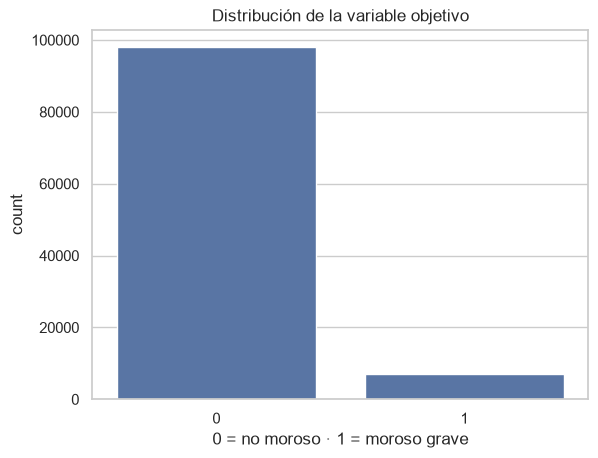

In [11]:
conteo = train[TARGET].value_counts().rename("clientes").to_frame()
conteo["porcentaje"] = (train[TARGET].value_counts(normalize=True) * 100).round(2)
display(conteo)

ax = sns.countplot(data=train, x=TARGET)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("0 = no moroso · 1 = moroso grave")
plt.show()

**Lectura:** la clase `1` es muy minoritaria (**datos desbalanceados**).
Consecuencias para el modelado:
- Accuracy no sirve: predecir siempre `0` ya daría ~93 %. Por eso la métrica es AUC-ROC.
- Conviene usar **validación cruzada estratificada** (mantiene la proporción en cada partición).
- Algunos modelos aceptan pesos de clase (`class_weight`).

## 5. Valores faltantes
¿Qué columnas tienen datos vacíos y cuántos?

In [12]:
faltantes = pd.DataFrame(
    {
        "n_faltantes": train[FEATS].isna().sum(),
        "% train": (train[FEATS].isna().mean() * 100).round(2),
        "% test": (test[FEATS].isna().mean() * 100).round(2),
    }
)
faltantes[faltantes["n_faltantes"] > 0]

,n_faltantes,% train,% test
MonthlyIncome,20828,19.84,19.78
NumberOfDependents,2771,2.64,2.56


In [13]:
# ¿Quien no reporta ingreso es más o menos moroso?
(
    train.groupby(train["MonthlyIncome"].isna())[TARGET]
    .agg(clientes="count", tasa_morosidad="mean")
    .rename_axis("ingreso_faltante")
    .round(4)
)

,clientes,tasa_morosidad
ingreso_faltante,,
False,84172,0.0695
True,20828,0.0561


**Lectura:** faltan datos en `MonthlyIncome` y en `NumberOfDependents`. El
patrón de faltantes es parecido en `train` y `test`.
Si la tasa de morosidad cambia cuando falta el ingreso, el hecho de que falte
**ya es información**: una opción es crear una columna indicadora
(`ingreso_faltante`) además de imputar (por ejemplo con la mediana).

## 6. Estadísticos descriptivos
Mínimo, máximo, media y percentiles de cada variable numérica.

In [14]:
train[FEATS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
RevolvingUtilizationOfUnsecuredLines,105000.0,6.41,273.64,0.0,0.0,0.03,0.15,0.56,1.09,50708.0
age,105000.0,52.29,14.78,0.0,24.0,41.00,52.00,63.00,87.00,103.0
NumberOfTime30-59DaysPastDueNotWorse,105000.0,0.43,4.29,0.0,0.0,0.00,0.00,0.00,4.00,98.0
DebtRatio,105000.0,358.33,2318.26,0.0,0.0,0.17,0.37,0.87,5011.01,329664.0
MonthlyIncome,84172.0,6645.49,15507.79,0.0,0.0,3400.00,5400.00,8208.00,25000.00,3008750.0
NumberOfOpenCreditLinesAndLoans,105000.0,8.44,5.13,0.0,0.0,5.00,8.00,11.00,24.00,58.0
NumberOfTimes90DaysLate,105000.0,0.27,4.26,0.0,0.0,0.00,0.00,0.00,3.00,98.0
NumberRealEstateLoansOrLines,105000.0,1.02,1.14,0.0,0.0,0.00,1.00,2.00,4.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,105000.0,0.25,4.25,0.0,0.0,0.00,0.00,0.00,2.00,98.0
NumberOfDependents,102229.0,0.76,1.11,0.0,0.0,0.00,0.00,1.00,4.00,13.0


**Cómo leer la tabla:** compara `50%` (mediana) con `mean` y con `max`.
- Si `max` es enorme frente al `99%`, hay **valores atípicos** (outliers).
- Si `mean` está muy lejos de la mediana, la distribución tiene cola larga.

Cosas que suelen llamar la atención aquí: `age` con mínimo 0,
`RevolvingUtilizationOfUnsecuredLines` muy por encima de 1 y las variables de
atraso con valores 96 o 98 (códigos especiales, no conteos reales).

## 7. Valores atípicos
Revisamos tres casos concretos.

In [15]:
print("Edad menor a 18:", (train["age"] < 18).sum())
print("Edad mayor a 90:", (train["age"] > 90).sum())
print("Utilización de líneas > 1:", (train["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("DebtRatio > 10:", (train["DebtRatio"] > 10).sum())

LATE = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
print("\nValores más altos en variables de atraso:")
for c in LATE:
    print(f"  {c}: {sorted(train[c].unique())[-4:]}")

Edad menor a 18: 1
Edad mayor a 90: 336
Utilización de líneas > 1: 2316
DebtRatio > 10: 20203

Valores más altos en variables de atraso:
  NumberOfTime30-59DaysPastDueNotWorse: [np.int64(12), np.int64(13), np.int64(96), np.int64(98)]
  NumberOfTime60-89DaysPastDueNotWorse: [np.int64(9), np.int64(11), np.int64(96), np.int64(98)]
  NumberOfTimes90DaysLate: [np.int64(14), np.int64(15), np.int64(96), np.int64(98)]


In [16]:
# Los valores 96 y 98 parecen códigos especiales: ¿cómo se comportan?
codigo = (train[LATE] >= 96).any(axis=1)
print("Filas con código 96/98:", codigo.sum())
print("Tasa de morosidad CON código   :", round(train.loc[codigo, TARGET].mean(), 4))
print("Tasa de morosidad SIN código   :", round(train.loc[~codigo, TARGET].mean(), 4))

Filas con código 96/98: 197
Tasa de morosidad CON código   : 0.5685
Tasa de morosidad SIN código   : 0.0659


**Lectura:** los 96/98 no son 96 atrasos reales: son marcas especiales y
además están asociadas a una tasa de morosidad muy distinta. Opciones:
tratarlos como categoría aparte, ponerlos en `NaN` y crear un indicador, o
recortar (*winsorizar*) el valor. Edades de 0 y razones de utilización o
deuda extremas se pueden recortar a un percentil alto (p. ej. 99).

## 8. Distribución de cada variable
Histogramas recortados al percentil 99 para que las colas extremas no
aplasten el gráfico.

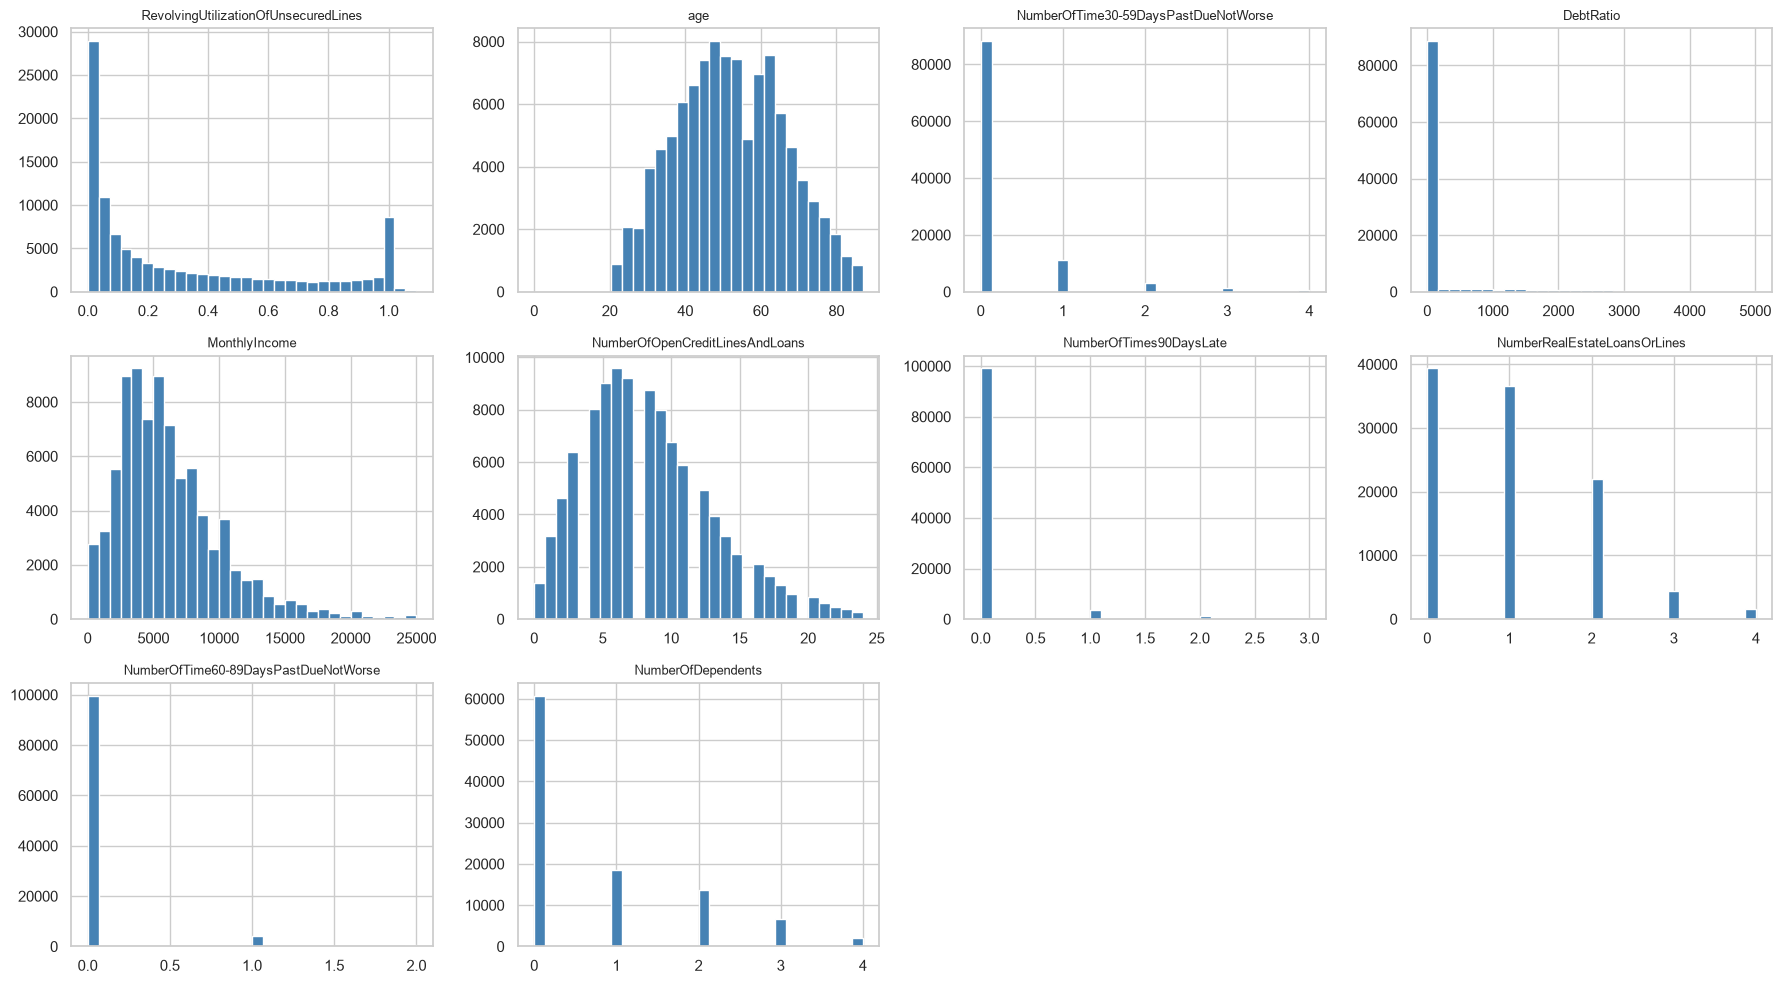

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), FEATS):
    serie = train[col].dropna()
    serie = serie[serie <= serie.quantile(0.99)]
    ax.hist(serie, bins=30, color="steelblue")
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(FEATS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Lectura:** la mayoría de las variables son muy asimétricas (muchos valores
pequeños y pocos grandes). Para modelos lineales ayuda aplicar `log1p` o
discretizar; los modelos de árboles no lo necesitan.

## 9. Relación de cada variable con el objetivo
¿Qué variables parecen separar a morosos de no morosos?

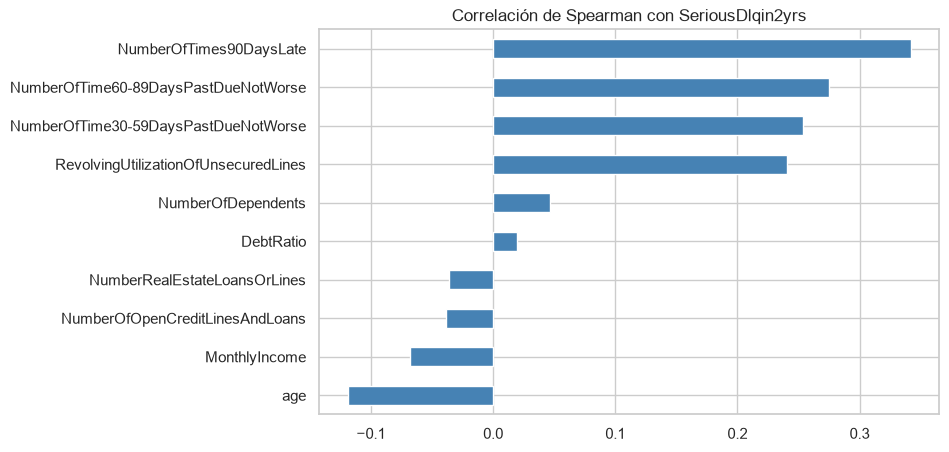

In [18]:
corr = train[FEATS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
corr.sort_values().plot.barh(figsize=(8, 5), color="steelblue")
plt.title("Correlación de Spearman con SeriousDlqin2yrs")
plt.show()

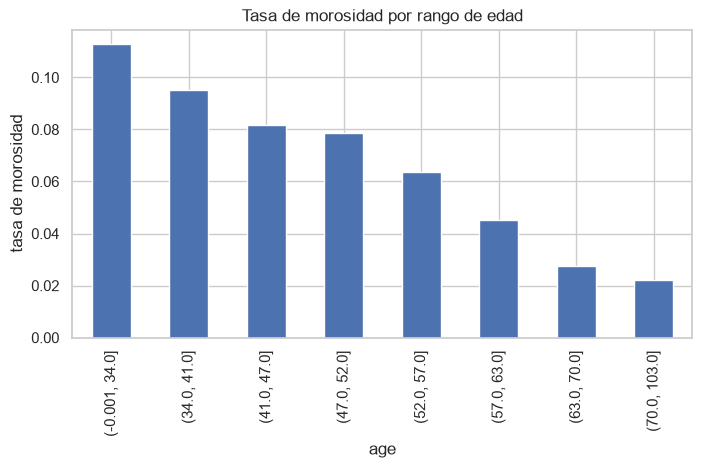

In [19]:
# Tasa de morosidad por rangos de edad (cuantiles)
rangos = pd.qcut(train["age"], 8)
train.groupby(rangos, observed=True)[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Tasa de morosidad por rango de edad")
plt.ylabel("tasa de morosidad")
plt.show()

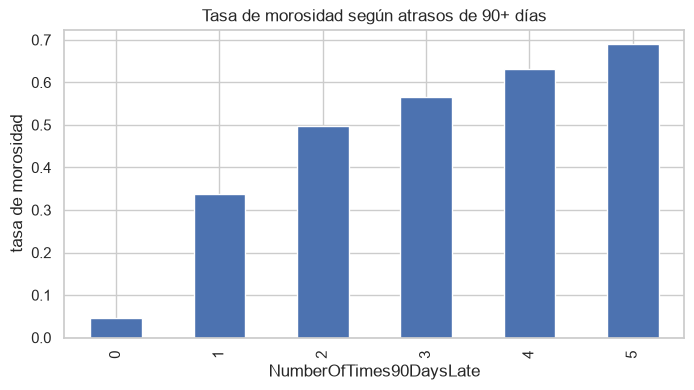

In [20]:
# Tasa de morosidad según número de atrasos de 90+ días (0 a 5)
t = train[train["NumberOfTimes90DaysLate"] <= 5]
t.groupby("NumberOfTimes90DaysLate")[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Tasa de morosidad según atrasos de 90+ días")
plt.ylabel("tasa de morosidad")
plt.show()

**Lectura:** las variables de atraso previo son las más relacionadas con la
morosidad futura, seguidas de la utilización de líneas de crédito
(`RevolvingUtilizationOfUnsecuredLines`). La edad tiene relación inversa (a
mayor edad, menor riesgo). Ideas de **ingeniería de variables** que salen de aquí:
- Suma total de atrasos (30-59 + 60-89 + 90+).
- Indicador de "tuvo algún atraso".
- Ingreso por dependiente (`MonthlyIncome / (NumberOfDependents + 1)`).
- Indicadores de faltante y de códigos 96/98.

## 10. Propuesta de preprocesamiento para la ingeniería de variables
Antes de construir el notebook de ingeniería de variables, decidimos **con
datos** dos cosas para cada variable:

1. Cómo tratar los valores faltantes y atípicos.
2. Si necesita escalado y de qué tipo.

**Dos tipos de transformación:**
- **Fijas (deterministas):** no aprenden nada de los datos, por ejemplo
  recortar a 2 o convertir 96/98 en `NaN`. Se pueden aplicar antes de la
  validación cruzada. Ya están en `src/features/features.py` (rama
  `feature/features-separabilidad`).
- **Aprendidas:** medianas, medias o desviaciones calculadas con los datos.
  Se ajustan **solo con el pliegue de entrenamiento** dentro de un
  `Pipeline`, para evitar fuga de datos.

### 10.1 Perfil de cada variable
- **Asimetría** (`skew`): 0 es simétrica; arriba de 1 tiene cola larga.
- **Asimetría con log:** cómo queda después de aplicar `log1p`.
- **% ceros:** si es muy alto, la variable se comporta casi como binaria.

In [21]:
perfil = pd.DataFrame(
    {
        "mín": train[FEATS].min(),
        "p99": train[FEATS].quantile(0.99),
        "máx": train[FEATS].max(),
        "asimetría": train[FEATS].skew(),
        "asimetría con log1p": np.log1p(train[FEATS].clip(lower=0)).skew(),
        "% ceros": (train[FEATS] == 0).mean() * 100,
        "% faltantes": train[FEATS].isna().mean() * 100,
    }
).round(2)
perfil.sort_values("asimetría", ascending=False)

,mín,p99,máx,asimetría,asimetría con log1p,% ceros,% faltantes
MonthlyIncome,0.0,25000.00,3008750.0,123.09,-4.38,1.09,19.84
RevolvingUtilizationOfUnsecuredLines,0.0,1.09,50708.0,98.41,11.74,7.29,0.00
DebtRatio,0.0,5011.01,329664.0,91.80,1.75,2.79,0.00
NumberOfTime60-89DaysPastDueNotWorse,0.0,2.00,98.0,22.81,10.64,94.95,0.00
NumberOfTimes90DaysLate,0.0,3.00,98.0,22.58,8.83,94.44,0.00
NumberOfTime30-59DaysPastDueNotWorse,0.0,4.00,98.0,22.12,4.32,84.05,0.00
NumberRealEstateLoansOrLines,0.0,4.00,54.0,3.99,0.25,37.51,0.00
NumberOfDependents,0.0,4.00,13.0,1.55,0.84,57.90,2.64
NumberOfOpenCreditLinesAndLoans,0.0,24.00,58.0,1.19,-0.75,1.30,0.00
age,0.0,87.00,103.0,0.19,-0.46,0.00,0.00


**Lectura:**
- `MonthlyIncome`, `RevolvingUtilizationOfUnsecuredLines` y `DebtRatio`
  tienen asimetría enorme (90 a 120): el máximo está a miles de veces del
  p99. Primero hay que **recortar** y después **transformar**.
- Las tres variables de atraso tienen entre 84 % y 95 % de ceros: se
  comportan casi como "tuvo o no tuvo atraso".
- `age` es casi simétrica: solo necesita estandarizarse.

### 10.2 Detalle del ingreso mensual: ¿qué tan dispersos están los datos?

In [22]:
ingreso = train["MonthlyIncome"].dropna()
q1, q3 = ingreso.quantile([0.25, 0.75])
iqr = q3 - q1
limite_atipico = q3 + 1.5 * iqr

dispersion = pd.Series(
    {
        "registros con ingreso": len(ingreso),
        "media": ingreso.mean(),
        "mediana": ingreso.median(),
        "desviación estándar": ingreso.std(),
        "coeficiente de variación (desv / media)": ingreso.std() / ingreso.mean(),
        "p5": ingreso.quantile(0.05),
        "p25 (Q1)": q1,
        "p75 (Q3)": q3,
        "p95": ingreso.quantile(0.95),
        "p99": ingreso.quantile(0.99),
        "p99.9": ingreso.quantile(0.999),
        "máximo": ingreso.max(),
        "rango intercuartil (IQR)": iqr,
        "límite de atípico (Q3 + 1.5·IQR)": limite_atipico,
        "% arriba del límite de atípico": (ingreso > limite_atipico).mean() * 100,
        "ingreso = 0": (ingreso == 0).sum(),
        "ingreso entre 1 y 100": ingreso.between(1, 100).sum(),
    },
    name="valor",
)
dispersion.round(2).to_frame()

,valor
registros con ingreso,84172.00
media,6645.49
mediana,5400.00
desviación estándar,15507.79
coeficiente de variación (desv / media),2.33
p5,1287.10
p25 (Q1),3400.00
p75 (Q3),8208.00
p95,14550.00
p99,25000.00


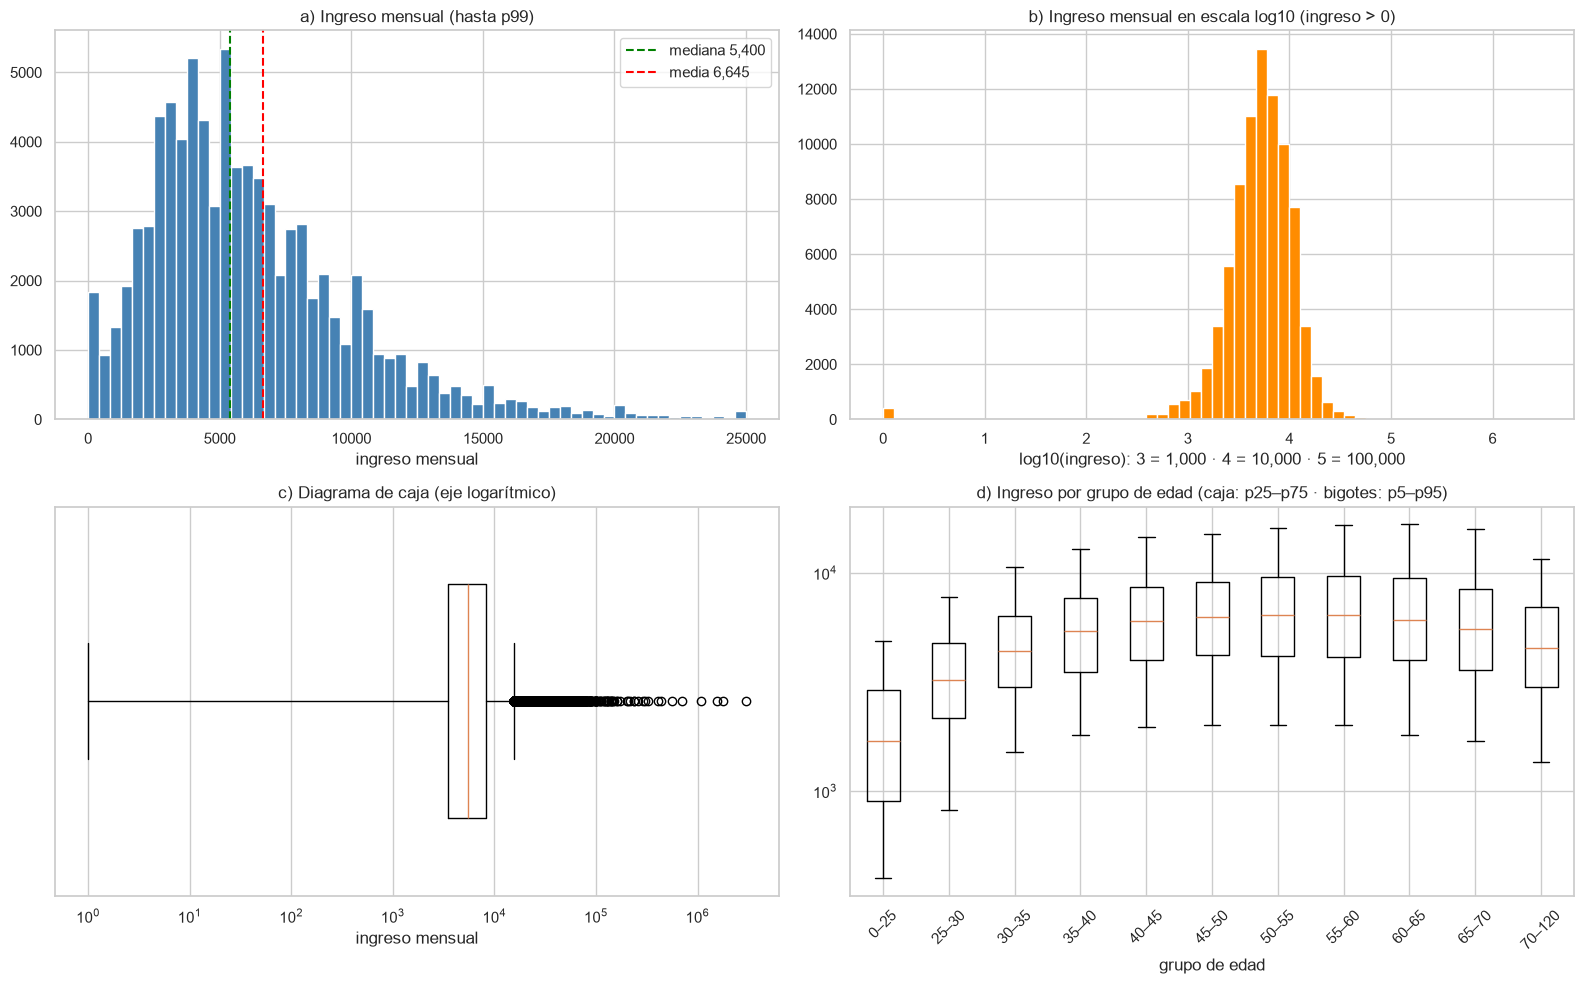

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
p99 = ingreso.quantile(0.99)

# a) Escala original, sin el 1 % más alto
ax = axes[0, 0]
ax.hist(ingreso[ingreso <= p99], bins=60, color="steelblue")
ax.axvline(ingreso.median(), color="green", ls="--", label=f"mediana {ingreso.median():,.0f}")
ax.axvline(ingreso.mean(), color="red", ls="--", label=f"media {ingreso.mean():,.0f}")
ax.set_title("a) Ingreso mensual (hasta p99)")
ax.set_xlabel("ingreso mensual")
ax.legend()

# b) Escala logarítmica: se ve la distribución completa
ax = axes[0, 1]
ax.hist(np.log10(ingreso[ingreso > 0]), bins=60, color="darkorange")
ax.set_title("b) Ingreso mensual en escala log10 (ingreso > 0)")
ax.set_xlabel("log10(ingreso): 3 = 1,000 · 4 = 10,000 · 5 = 100,000")

# c) Caja: dónde se concentra el 50 % central y cuántos atípicos hay
ax = axes[1, 0]
ax.boxplot([ingreso[ingreso > 0].to_numpy()], orientation="horizontal", widths=0.6)
ax.set_xscale("log")
ax.set_title("c) Diagrama de caja (eje logarítmico)")
ax.set_xlabel("ingreso mensual")
ax.set_yticks([])

# d) Dispersión por grupo de edad
ax = axes[1, 1]
CORTES_EDAD = [0, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 120]
con_edad = train.loc[train["MonthlyIncome"] > 0, ["age", "MonthlyIncome"]].copy()
con_edad["grupo_edad"] = pd.cut(con_edad["age"], CORTES_EDAD)
orden_grupos = con_edad["grupo_edad"].cat.categories
ax.boxplot(
    [con_edad.loc[con_edad["grupo_edad"] == g, "MonthlyIncome"].to_numpy()
     for g in orden_grupos],
    tick_labels=[f"{int(g.left)}–{int(g.right)}" for g in orden_grupos],
    whis=(5, 95),
    showfliers=False,
)
ax.set_yscale("log")
ax.set_title("d) Ingreso por grupo de edad (caja: p25–p75 · bigotes: p5–p95)")
ax.set_xlabel("grupo de edad")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Lectura:** el ingreso está **muy disperso**.
- La desviación estándar (15,508) es más del doble de la media (6,646):
  coeficiente de variación de 2.3. Arriba de 1 ya se considera alta.
- La media está por encima de la mediana (5,400) porque unos pocos ingresos
  enormes la jalan: el máximo es 3 millones, 120 veces el p99 (25,000).
- El 50 % central está entre 3,400 y 8,208 (IQR de 4,808), y el 4.1 % queda
  arriba del límite de atípico (15,420).
- En el extremo bajo hay 1,143 ingresos en 0 y 468 entre 1 y 100, que no
  son ingresos mensuales creíbles.
- En escala logarítmica (b) la distribución se ve casi normal: por eso se
  usa `log1p` antes de escalar.
- La gráfica (d) confirma que el ingreso cambia con la edad, pero dentro de
  cada grupo la dispersión sigue siendo amplia.

### 10.3 Valores faltantes
Faltan datos en `MonthlyIncome` (19.8 %) y `NumberOfDependents` (2.6 %).

**a) ¿Los faltantes de las dos variables están relacionados?**

In [24]:
falta_ingreso = train["MonthlyIncome"].isna()
falta_dependientes = train["NumberOfDependents"].isna()
pd.crosstab(
    falta_ingreso.rename("falta ingreso"),
    falta_dependientes.rename("faltan dependientes"),
    margins=True,
    margins_name="total",
)

faltan dependientes,False,True,total
falta ingreso,,,
False,84172,0,84172
True,18057,2771,20828
total,102229,2771,105000


**Lectura:** todos los clientes sin `NumberOfDependents` tampoco tienen
ingreso. Es el mismo problema de captura, y por eso los indicadores de
faltante son importantes.

**b) Cuando falta el ingreso, ¿está informado el `DebtRatio`?**

In [25]:
debt_sin_ingreso = train.loc[falta_ingreso, "DebtRatio"]
pd.Series(
    {
        "registros sin ingreso": len(debt_sin_ingreso),
        "con DebtRatio informado": debt_sin_ingreso.notna().sum(),
        "con DebtRatio = 0": (debt_sin_ingreso == 0).sum(),
        "% de valores enteros": (debt_sin_ingreso == debt_sin_ingreso.round()).mean() * 100,
    },
    name="valor",
).round(1).to_frame()

,valor
registros sin ingreso,20828.0
con DebtRatio informado,20828.0
con DebtRatio = 0,1162.0
% de valores enteros,100.0


In [26]:
pd.DataFrame(
    {
        "DebtRatio mediano": train.groupby(falta_ingreso)["DebtRatio"].median(),
        "% con DebtRatio > 1": train["DebtRatio"].gt(1).groupby(falta_ingreso).mean()
        * 100,
    }
).rename_axis("falta ingreso").round(2)

,DebtRatio mediano,% con DebtRatio > 1
falta ingreso,,
False,0.3,6.07
True,1158.0,93.79


**Lectura:** **sí**: los 20,828 registros sin ingreso tienen `DebtRatio`
informado (1,162 en cero). Pero ahí no es una razón:
- Con ingreso, el `DebtRatio` mediano es 0.30. Sin ingreso es **1,158** y
  el 94 % supera 1.
- El 100 % son números enteros, como un monto en dinero.

Todo indica que, sin ingreso, el sistema guardó el **monto mensual de la
deuda** (la razón dividida entre 1). Si la hipótesis es correcta, su
distribución debe parecerse a la del monto de deuda de los clientes que sí
tienen ingreso (`DebtRatio × MonthlyIncome`):

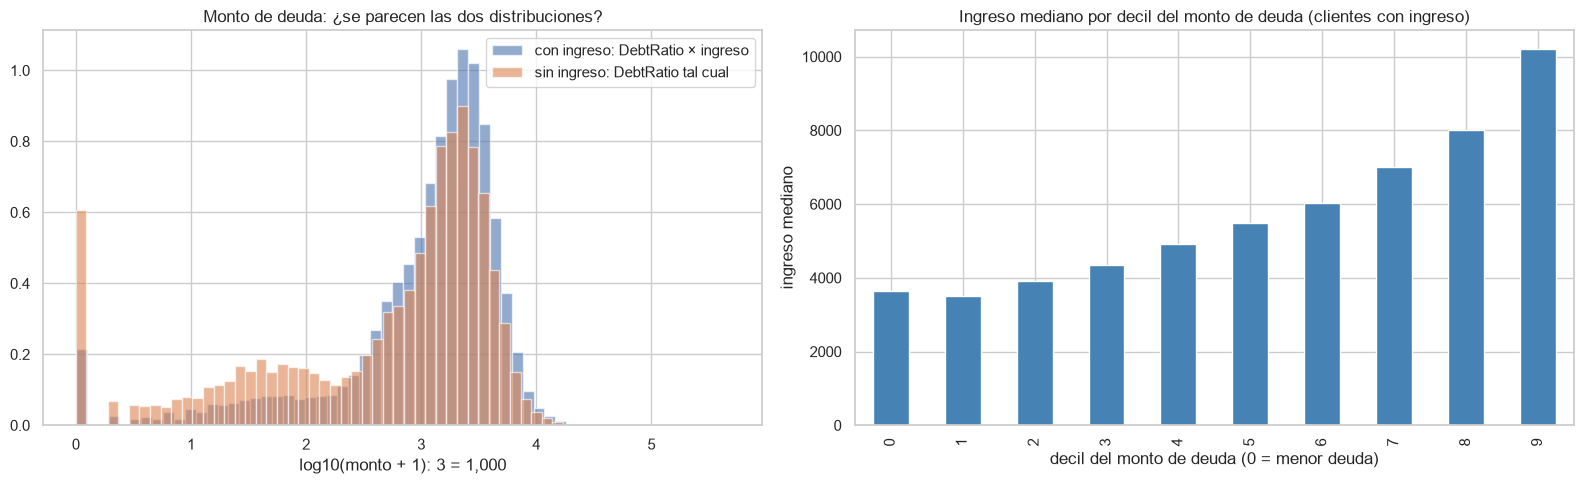

Correlación de Spearman entre monto de deuda e ingreso: 0.498


In [27]:
con_ingreso = train[train["MonthlyIncome"] > 0].copy()
con_ingreso["monto_deuda"] = con_ingreso["DebtRatio"] * con_ingreso["MonthlyIncome"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.hist(np.log10(con_ingreso["monto_deuda"] + 1), bins=60, alpha=0.6, density=True,
        label="con ingreso: DebtRatio × ingreso")
ax.hist(np.log10(debt_sin_ingreso + 1), bins=60, alpha=0.6, density=True,
        label="sin ingreso: DebtRatio tal cual")
ax.set_title("Monto de deuda: ¿se parecen las dos distribuciones?")
ax.set_xlabel("log10(monto + 1): 3 = 1,000")
ax.legend()

# ¿El monto de deuda dice algo del ingreso?
deciles_deuda = pd.qcut(con_ingreso["monto_deuda"].rank(method="first"), 10, labels=False)
ax = axes[1]
con_ingreso.groupby(deciles_deuda)["MonthlyIncome"].median().plot(
    kind="bar", color="steelblue", ax=ax
)
ax.set_title("Ingreso mediano por decil del monto de deuda (clientes con ingreso)")
ax.set_xlabel("decil del monto de deuda (0 = menor deuda)")
ax.set_ylabel("ingreso mediano")
plt.tight_layout()
plt.show()

print(
    "Correlación de Spearman entre monto de deuda e ingreso:",
    round(con_ingreso[["monto_deuda", "MonthlyIncome"]].corr("spearman").iloc[0, 1], 3),
)

**Lectura:**
- La parte principal de las dos distribuciones coincide (izquierda): ambas
  se concentran alrededor de 1,000–3,000, lo que respalda la hipótesis de que,
  sin ingreso, `DebtRatio` es el monto de la deuda. La diferencia es que los
  clientes sin ingreso tienen más montos bajos (10 a 100) y más ceros: son
  clientes con poca o ninguna deuda.
- **Sí se puede inferir parcialmente el ingreso a partir de este campo:**
  el ingreso mediano sube de forma ordenada con el monto de deuda
  (derecha), con una correlación de Spearman de 0.50, la más alta de
  cualquier variable con el ingreso. Quien paga más deuda suele ganar más.
- No es una fórmula exacta: no conocemos la razón real de esas personas,
  así que solo podemos estimar un ingreso típico para su nivel de deuda.

**c) ¿El ingreso cambia con la edad y con los créditos hipotecarios?**

,ingreso_mediano,pct_sin_ingreso,dependientes_medianos,dependientes_promedio
age,,,,
"(0, 25]",1600.0,20.41,0.0,0.14
"(25, 30]",3200.0,14.30,0.0,0.41
"(30, 35]",4350.0,12.82,0.0,0.78
"(35, 40]",5316.0,14.18,1.0,1.18
"(40, 45]",5978.0,14.74,1.0,1.34
"(45, 50]",6250.0,16.34,1.0,1.24
"(50, 55]",6300.0,18.24,0.0,0.94
"(55, 60]",6333.0,21.12,0.0,0.61
"(60, 65]",6000.0,24.80,0.0,0.40


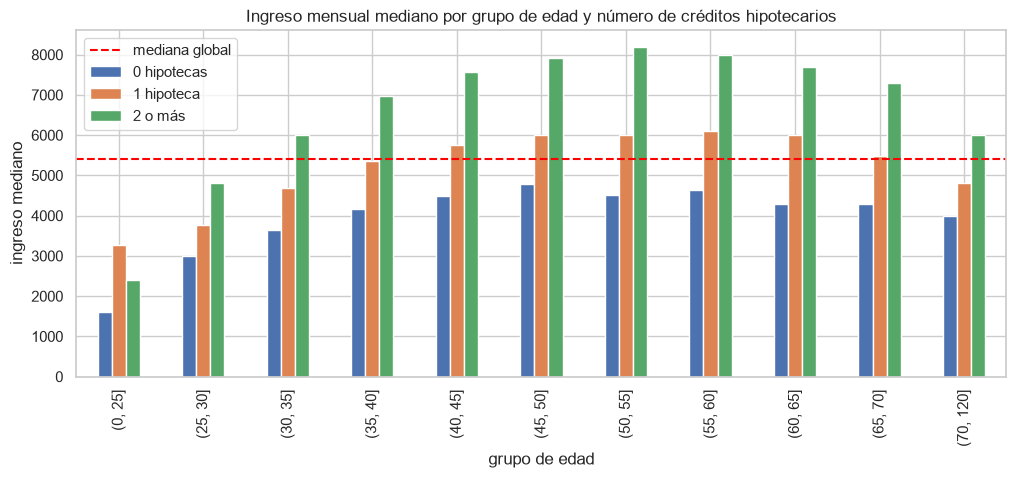

NumberRealEstateLoansOrLines,0 hipotecas,1 hipoteca,2 o más
age,,,
"(0, 25]",1600.0,3267.0,2400.0
"(25, 30]",3000.0,3764.0,4800.0
"(30, 35]",3632.0,4676.0,6000.0
"(35, 40]",4166.0,5355.0,6982.0
"(40, 45]",4500.0,5750.0,7570.0
"(45, 50]",4789.0,6000.0,7916.0
"(50, 55]",4520.0,6000.0,8200.0
"(55, 60]",4634.0,6105.0,8000.0
"(60, 65]",4300.0,6000.0,7702.0


In [28]:
grupo_edad = pd.cut(train["age"], CORTES_EDAD)
ingreso_por_edad = train.groupby(grupo_edad, observed=True).agg(
    ingreso_mediano=("MonthlyIncome", "median"),
    pct_sin_ingreso=("MonthlyIncome", lambda s: s.isna().mean() * 100),
    dependientes_medianos=("NumberOfDependents", "median"),
    dependientes_promedio=("NumberOfDependents", "mean"),
)
display(ingreso_por_edad.round(2))

hipotecas = train["NumberRealEstateLoansOrLines"].clip(upper=2).map(
    {0: "0 hipotecas", 1: "1 hipoteca", 2: "2 o más"}
)
tabla_edad_hipotecas = train.pivot_table(
    index=grupo_edad, columns=hipotecas, values="MonthlyIncome",
    aggfunc="median", observed=True,
)
ax = tabla_edad_hipotecas.plot(kind="bar", figsize=(12, 4.5))
ax.axhline(train["MonthlyIncome"].median(), color="red", ls="--", label="mediana global")
ax.set_title("Ingreso mensual mediano por grupo de edad y número de créditos hipotecarios")
ax.set_xlabel("grupo de edad")
ax.set_ylabel("ingreso mediano")
ax.legend()
plt.show()
tabla_edad_hipotecas.round(0)

**Lectura:** el ingreso mediano va de 1,600 (≤ 25 años) a 6,333 (55–60
años). Y **dentro de cada grupo de edad, tener créditos hipotecarios marca
una diferencia grande**: quien tiene 2 o más hipotecas gana bastante más que
quien no tiene ninguna. Con una sola mediana global (5,400) se le asignaría
el mismo ingreso a todos. Además, los mayores de 60 son los que más ingreso
dejan en blanco (25–31 %).

**d) ¿Qué estrategia imputa mejor el ingreso?**

Tomamos los clientes que **sí** tienen ingreso (> 0), les "ocultamos" el
30 % y medimos qué tan cerca queda cada estrategia del valor real. Usamos
escala logarítmica porque el ingreso es muy asimétrico; menor error es mejor.
Todas las medianas y los cortes de deciles se calculan solo con el 70 % de
ajuste.

In [29]:
from sklearn.model_selection import train_test_split

base = con_ingreso.copy()
# Número de grupo de edad; la edad 0 (fuera de los cortes) va al grupo más joven
base["grupo_edad"] = (
    pd.cut(base["age"], CORTES_EDAD, labels=False).fillna(0).astype(int).astype(str)
)
base["hipotecas"] = base["NumberRealEstateLoansOrLines"].clip(upper=2).astype(str)
ajuste, prueba = train_test_split(base, test_size=0.3, random_state=42)

# Deciles del monto de deuda con cortes aprendidos solo en el ajuste
cortes_deuda = np.quantile(ajuste["monto_deuda"], np.linspace(0, 1, 11))
cortes_deuda[0], cortes_deuda[-1] = -np.inf, np.inf
for df in (ajuste, prueba):
    df["decil_deuda"] = pd.cut(df["monto_deuda"], cortes_deuda, labels=False).astype(str)
    df["edad_hipotecas"] = df["grupo_edad"] + "_" + df["hipotecas"]
    df["edad_deuda"] = df["grupo_edad"] + "_" + df["decil_deuda"]

mediana_global = ajuste["MonthlyIncome"].median()
log_real = np.log1p(prueba["MonthlyIncome"])


def error_imputacion(grupo: str | None) -> float:
    """Error absoluto medio en log1p al imputar con la mediana de un grupo.

    Args:
        grupo: Columna que define los grupos; ``None`` usa la mediana global.

    Returns:
        Error absoluto medio entre el ingreso real e imputado en escala log1p.
    """
    if grupo is None:
        imputado = pd.Series(mediana_global, index=prueba.index)
    else:
        medianas = ajuste.groupby(grupo)["MonthlyIncome"].median()
        imputado = prueba[grupo].map(medianas).fillna(mediana_global)
    return float((log_real - np.log1p(imputado)).abs().mean())


estrategias = {
    "mediana global": None,
    "mediana por grupo de edad": "grupo_edad",
    "⭐ mediana por edad + n.º de créditos hipotecarios": "edad_hipotecas",
    "mediana por decil del monto de deuda": "decil_deuda",
    "mediana por edad + decil del monto de deuda": "edad_deuda",
}
comparacion = pd.DataFrame(
    {
        "grupos": [1 if g is None else ajuste[g].nunique() for g in estrategias.values()],
        "error (MAE en log)": [error_imputacion(g) for g in estrategias.values()],
    },
    index=list(estrategias),
)
comparacion["mejora vs global (%)"] = (
    1 - comparacion["error (MAE en log)"] / comparacion["error (MAE en log)"].iloc[0]
) * 100
comparacion.round(3)

,grupos,error (MAE en log),mejora vs global (%)
mediana global,1,0.577,0.000
mediana por grupo de edad,11,0.543,5.915
⭐ mediana por edad + n.º de créditos hipotecarios,33,0.515,10.611
mediana por decil del monto de deuda,10,0.498,13.678
mediana por edad + decil del monto de deuda,109,0.484,16.125


> ### Dos estrategias de imputación del ingreso → dos variables de ingreso
>
> | | ⭐ Estrategia A (principal) | 🔷 Estrategia B (alternativa) |
> | --- | --- | --- |
> | **Grupos** | Edad × n.º de créditos hipotecarios (0, 1, 2+) | Edad × decil del monto mensual de deuda |
> | **N.º de grupos** | 33 | 109 |
> | **Mejora vs mediana global** | 10.6 % | **16.1 %** |
> | **Variable nueva** | `income_imp_age_mortgage` | `income_imp_age_debt` |
> | **Ventaja** | Fácil de explicar; usa variables siempre informadas y confiables | Imputa mejor: el monto de deuda es el mejor predictor del ingreso (Spearman 0.50) |
> | **Riesgo** | Imputa con menos precisión | Depende de la hipótesis de que, sin ingreso, `DebtRatio` es el monto de deuda (bien respaldada en 10.3 b, pero no comprobable directamente) |
>
> **Propuesta:** no elegir una sola. En la ingeniería de variables se
> construyen **las dos variables de ingreso** y se compara por AUC en
> validación cruzada usar A, B o ambas. Para el monto de deuda:
> - Con ingreso > 0: `DebtRatio × MonthlyIncome`.
> - Sin ingreso o con ingreso 0: `DebtRatio` tal cual (ya es el monto).

En todos los casos se agrega el indicador `income_missing`: ninguna mediana
adivina bien el ingreso de una persona.

**¿Qué tan distintas quedan las dos variables?** Aplicamos ambas
estrategias a los 20,828 clientes sin ingreso. Aquí las medianas se calculan
con todos los clientes con ingreso solo para explorar; en el notebook 03 se
calcularán dentro de cada pliegue.

,count,mean,std,min,10%,25%,50%,75%,90%,max
income_imp_age_mortgage,20828.0,5397.0,1481.0,1698.0,4000.0,4364.0,5416.0,6000.0,7800.0,8266.0
income_imp_age_debt,20828.0,5360.0,1991.0,1200.0,3750.0,4000.0,4502.0,6291.0,8167.0,11359.0


Correlación de Spearman entre A y B: 0.837
Clientes donde A y B difieren más de 30 %: 11.9%


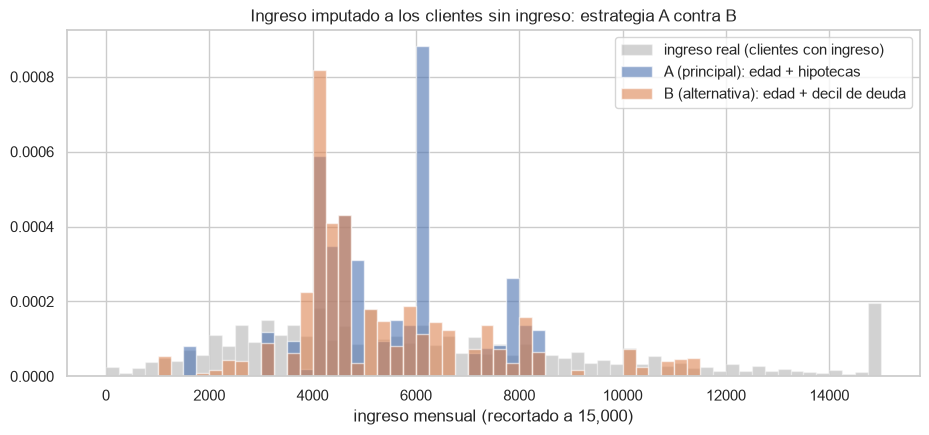

In [30]:
conocidos = base.copy()
cortes_deuda_todos = np.quantile(conocidos["monto_deuda"], np.linspace(0, 1, 11))
cortes_deuda_todos[0], cortes_deuda_todos[-1] = -np.inf, np.inf

sin_ingreso_df = train[falta_ingreso].copy()
sin_ingreso_df["monto_deuda"] = sin_ingreso_df["DebtRatio"]  # ya es el monto
sin_ingreso_df["grupo_edad"] = (
    pd.cut(sin_ingreso_df["age"], CORTES_EDAD, labels=False)
    .fillna(0)
    .astype(int)
    .astype(str)
)
sin_ingreso_df["hipotecas"] = (
    sin_ingreso_df["NumberRealEstateLoansOrLines"].clip(upper=2).astype(str)
)
for df in (conocidos, sin_ingreso_df):
    df["decil_deuda"] = pd.cut(
        df["monto_deuda"], cortes_deuda_todos, labels=False
    ).astype(str)
    df["edad_hipotecas"] = df["grupo_edad"] + "_" + df["hipotecas"]
    df["edad_deuda"] = df["grupo_edad"] + "_" + df["decil_deuda"]

mediana_conocidos = conocidos["MonthlyIncome"].median()
sin_ingreso_df["income_imp_age_mortgage"] = (
    sin_ingreso_df["edad_hipotecas"]
    .map(conocidos.groupby("edad_hipotecas")["MonthlyIncome"].median())
    .fillna(mediana_conocidos)
)
sin_ingreso_df["income_imp_age_debt"] = (
    sin_ingreso_df["edad_deuda"]
    .map(conocidos.groupby("edad_deuda")["MonthlyIncome"].median())
    .fillna(mediana_conocidos)
)

imputados = sin_ingreso_df[["income_imp_age_mortgage", "income_imp_age_debt"]]
display(imputados.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(0))
diferencia_rel = (
    imputados["income_imp_age_debt"] - imputados["income_imp_age_mortgage"]
).abs() / imputados["income_imp_age_mortgage"]
print(
    "Correlación de Spearman entre A y B:",
    round(imputados.corr("spearman").iloc[0, 1], 3),
)
print(f"Clientes donde A y B difieren más de 30 %: {(diferencia_rel > 0.3).mean():.1%}")

fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.linspace(0, 15_000, 61)
ax.hist(conocidos["MonthlyIncome"].clip(upper=15_000), bins=bins, density=True,
        alpha=0.35, color="gray", label="ingreso real (clientes con ingreso)")
ax.hist(imputados["income_imp_age_mortgage"], bins=bins, density=True, alpha=0.6,
        label="A (principal): edad + hipotecas")
ax.hist(imputados["income_imp_age_debt"], bins=bins, density=True, alpha=0.6,
        label="B (alternativa): edad + decil de deuda")
ax.set_title("Ingreso imputado a los clientes sin ingreso: estrategia A contra B")
ax.set_xlabel("ingreso mensual (recortado a 15,000)")
ax.legend()
plt.show()

**Lectura:**
- Las dos variables se parecen (Spearman 0.84), pero **no son iguales**: en
  el 11.9 % de los clientes difieren más de 30 %. B aporta información que A
  no tiene.
- **A** solo puede tomar 33 valores y se amontona en pocos picos (por
  ejemplo, 6,000); su mediana es 5,416.
- **B** está más repartida (de 1,200 a 11,359, desviación 1,991 contra
  1,481) y se parece más a la forma del ingreso real. Su mediana es menor
  (4,502) porque los clientes sin ingreso tienen montos de deuda más bajos
  (sección 10.3 b).
- Ambas son más angostas que el ingreso real: imputar con medianas siempre
  reduce la dispersión. Por eso se acompañan del indicador `income_missing`.
- Si se usan **las dos** en una regresión logística, estarán correlacionadas;
  la regularización (L1/L2) maneja esa redundancia, y el experimento dirá si
  vale la pena conservar ambas.

### 10.4 Atípicos que se corrigen antes de imputar o escalar

In [31]:
rangos_util = pd.cut(
    train["RevolvingUtilizationOfUnsecuredLines"], [-1, 0.3, 0.7, 1, 2, 10, np.inf]
)
display(
    train.groupby(rangos_util, observed=True)[TARGET]
    .agg(clientes="count", tasa_morosidad="mean")
    .round(3)
)
print("Edad < 18:", (train["age"] < 18).sum())
print("Ingreso = 0:", (train["MonthlyIncome"] == 0).sum())
print("Filas con atrasos 96/98:", (train[LATE] >= 96).any(axis=1).sum())
print("Atraso máximo real (sin 96/98):", train.loc[~codigo, LATE].max().to_dict())

,clientes,tasa_morosidad
RevolvingUtilizationOfUnsecuredLines,,
"(-1.0, 0.3]",64955,0.022
"(0.3, 0.7]",19047,0.074
"(0.7, 1.0]",18682,0.178
"(1.0, 2.0]",2051,0.396
"(2.0, 10.0]",92,0.304
"(10.0, inf]",173,0.064


Edad < 18: 1
Ingreso = 0: 1143
Filas con atrasos 96/98: 197
Atraso máximo real (sin 96/98): {'NumberOfTime30-59DaysPastDueNotWorse': 13, 'NumberOfTime60-89DaysPastDueNotWorse': 11, 'NumberOfTimes90DaysLate': 15}


**Lectura:**
- **Utilización:** el riesgo sube hasta 1–2 (40 % de morosidad) y luego
  **baja** para valores > 10 (6 %). Esos valores no son utilizaciones reales,
  son errores de captura. Recortar en 2 conserva la señal; un indicador
  `util_gt1` captura el exceso.
- **Edad < 18:** solo hay un registro (edad 0). Se pone en `NaN` y se imputa.
- **Ingreso = 0:** 1,143 clientes. No es faltante, pero hace infinita la
  razón de deuda; lleva su propio indicador.
- **Atrasos 96/98:** 197 filas, siempre en las tres columnas a la vez. Se
  ponen en `NaN` con indicador `late_sentinel`; el atraso real máximo es 15.

### 10.5 Escalado que vamos a usar
El escalado solo lo necesitan los modelos que usan coeficientes o
distancias, en nuestro caso la **regresión logística con regularización**
(L1/L2 penaliza por igual a todos los coeficientes, así que las variables
deben estar en la misma escala). Los **modelos de árboles no se escalan**.

| Técnica | Papel | Dónde se usa |
| --- | --- | --- |
| `log1p` | Paso previo: comprime la cola larga | Ingreso, `DebtRatio`, monto de deuda y atrasos |
| `StandardScaler` (estandarizar) | **Opción base**: media 0 y desviación 1 | Todas las variables continuas, después de recortar y `log1p` |
| `RobustScaler` | Comparación: usa mediana e IQR, resiste atípicos | Experimento contra `StandardScaler` (no en atrasos: su IQR es 0) |
| `QuantileTransformer` | Comparación: convierte a percentiles | Experimento contra `StandardScaler` |

### 10.6 Propuesta por variable
Orden de aplicación: **1) limpieza fija → 2) imputación → 3) transformación
→ 4) escalado**. Los pasos 2 y 4 se aprenden en cada pliegue.

| Variable | Problema detectado | Faltantes | Atípicos (fijo) | Transformación | Escalado | Alternativa a probar |
| --- | --- | --- | --- | --- | --- | --- |
| `RevolvingUtilizationOfUnsecuredLines` | Asimetría 98; valores > 10 son errores | — | Recortar a [0, 2] + `util_gt1` | — | `StandardScaler` | `QuantileTransformer` |
| `age` | 1 registro con edad 0 | Mediana (1 fila) | Edad < 18 → `NaN` | — | `StandardScaler` | — |
| `NumberOfTime30-59DaysPastDueNotWorse` | 84 % ceros; códigos 96/98 | 96/98 → 0 + `late_sentinel` | 96/98 → `NaN` | Recortar a p99.9 + `log1p` | `StandardScaler` | Binarizar (0 / ≥ 1) |
| `NumberOfTime60-89DaysPastDueNotWorse` | 95 % ceros; códigos 96/98 | Igual que arriba | Igual que arriba | Igual que arriba | `StandardScaler` | Igual que arriba |
| `NumberOfTimes90DaysLate` | 94 % ceros; códigos 96/98 | Igual que arriba | Igual que arriba | Igual que arriba | `StandardScaler` | Igual que arriba |
| `DebtRatio` | Es un **monto** cuando falta el ingreso | — | Separar en `debt_ratio_valid` (≤ 10) y `debt_amount` | `log1p` a ambas | `StandardScaler` | `RobustScaler` |
| `MonthlyIncome` | 19.8 % faltante; 1,143 en 0; muy disperso (CV 2.3) | **Dos variables:** ⭐ `income_imp_age_mortgage` (edad + hipotecas) y 🔷 `income_imp_age_debt` (edad + decil de deuda), ambas con `income_missing` | Recortar a p99 (25,000) + `income_zero` | `log1p` a ambas | `StandardScaler` | Usar solo A, solo B o ambas |
| `NumberOfOpenCreditLinesAndLoans` | Asimetría moderada (1.2) | — | Recortar a p99 (24) | — | `StandardScaler` | — |
| `NumberRealEstateLoansOrLines` | Máximo 54 contra p99 de 4 | — | Recortar a 5 | — | `StandardScaler` | — |
| `NumberOfDependents` | 2.6 % faltante (siempre junto con ingreso) | Mediana por grupo de edad (0 o 1) + `dependents_missing` | Recortar a 5 | — | `StandardScaler` | Imputar 0 (la moda) |

**Para modelos de árboles** (XGBoost, `HistGradientBoostingClassifier`):
misma limpieza fija y mismos indicadores, **sin escalado**. Estos modelos
manejan `NaN` directamente, así que imputar es opcional: conviene comparar
ambas opciones.

### 10.7 PCA: ¿dónde está el jugo en los datos?
El **Análisis de Componentes Principales (PCA)** combina las variables en
nuevos ejes, los *componentes principales*, ordenados de mayor a menor
varianza. El primer componente es la dirección donde los datos más varían,
es decir, donde hay **más jugo en los datos**; el segundo es la siguiente, y
así sucesivamente.

Como PCA mide varianza, se aplica sobre los datos ya preparados según la
propuesta: limpieza fija, imputación sencilla con la mediana, `log1p` y
`StandardScaler`. Sin escalar, el ingreso (en miles) dominaría solo por su
escala.

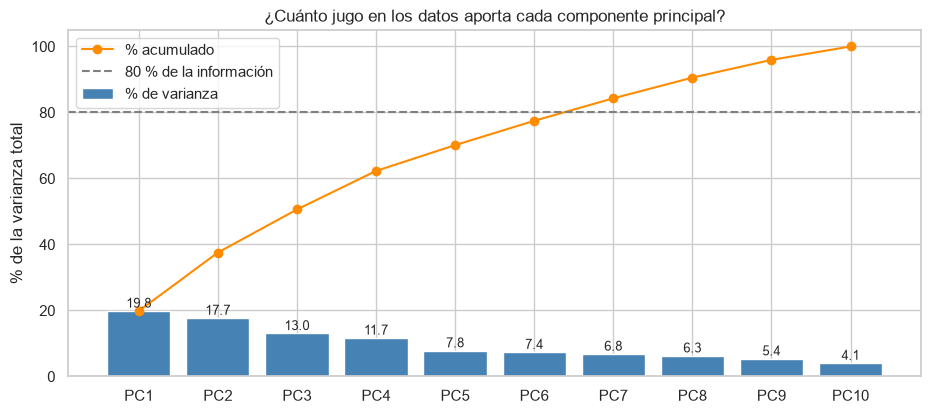

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
% varianza,19.8,17.7,13.0,11.7,7.8,7.4,6.8,6.3,5.4,4.1
% acumulado,19.8,37.6,50.6,62.3,70.1,77.5,84.3,90.6,95.9,100.0


In [32]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

datos_pca = train[FEATS].copy()
datos_pca[LATE] = datos_pca[LATE].where(datos_pca[LATE] < 96, 0)
datos_pca.loc[datos_pca["age"] < 18, "age"] = np.nan
datos_pca["RevolvingUtilizationOfUnsecuredLines"] = datos_pca[
    "RevolvingUtilizationOfUnsecuredLines"
].clip(0, 2)
sin_ingreso = datos_pca["MonthlyIncome"].isna() | (datos_pca["MonthlyIncome"] <= 0)
datos_pca["DebtRatio"] = datos_pca["DebtRatio"].where(~sin_ingreso).clip(upper=10)
datos_pca["MonthlyIncome"] = datos_pca["MonthlyIncome"].clip(upper=25_000)
datos_pca["NumberOfOpenCreditLinesAndLoans"] = datos_pca[
    "NumberOfOpenCreditLinesAndLoans"
].clip(upper=24)
datos_pca["NumberRealEstateLoansOrLines"] = datos_pca[
    "NumberRealEstateLoansOrLines"
].clip(upper=5)
datos_pca["NumberOfDependents"] = datos_pca["NumberOfDependents"].clip(upper=5)
datos_pca = datos_pca.fillna(datos_pca.median())
COLS_LOG = LATE + ["DebtRatio", "MonthlyIncome"]
datos_pca[COLS_LOG] = np.log1p(datos_pca[COLS_LOG])

matriz = StandardScaler().fit_transform(datos_pca)
pca = PCA(random_state=42).fit(matriz)
varianza = pd.DataFrame(
    {
        "% varianza": pca.explained_variance_ratio_ * 100,
        "% acumulado": pca.explained_variance_ratio_.cumsum() * 100,
    },
    index=[f"PC{i}" for i in range(1, len(FEATS) + 1)],
)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(varianza.index, varianza["% varianza"], color="steelblue", label="% de varianza")
ax.plot(varianza.index, varianza["% acumulado"], color="darkorange", marker="o",
        label="% acumulado")
ax.axhline(80, color="gray", ls="--", label="80 % de la información")
for i, v in enumerate(varianza["% varianza"]):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=9)
ax.set_title("¿Cuánto jugo en los datos aporta cada componente principal?")
ax.set_ylabel("% de la varianza total")
ax.legend()
plt.show()
varianza.round(1).T

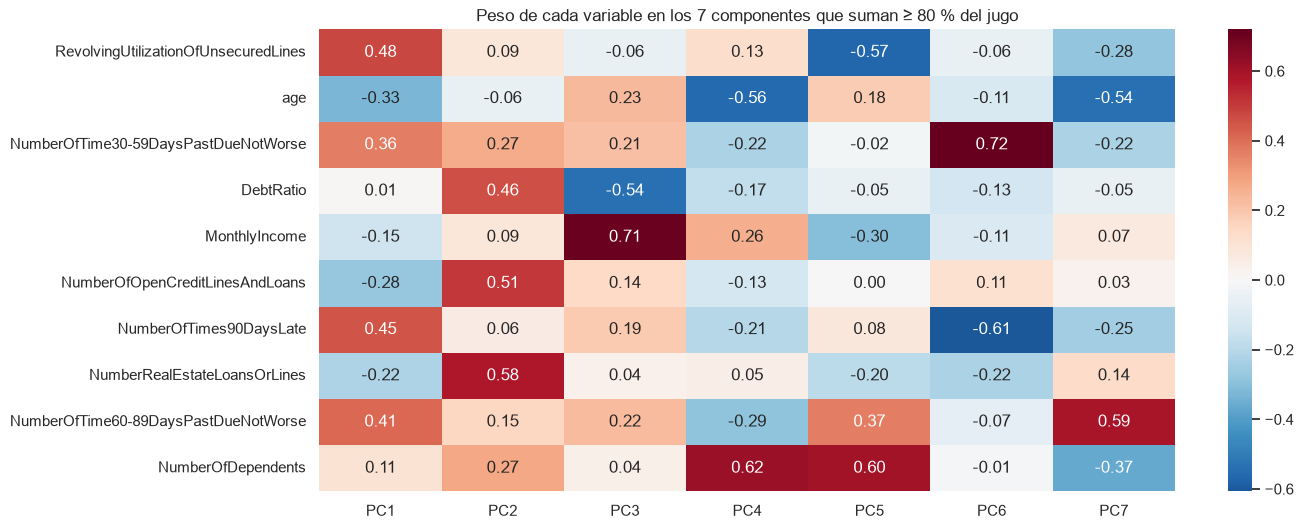

Componentes necesarios para llegar a 80 % de la varianza: 7 de 10


In [33]:
n_80 = int((varianza["% acumulado"] < 80).sum() + 1)
cargas = pd.DataFrame(
    pca.components_[:n_80].T,
    index=FEATS,
    columns=[f"PC{i}" for i in range(1, n_80 + 1)],
)
fig, ax = plt.subplots(figsize=(1.4 * n_80 + 4, 6))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title(f"Peso de cada variable en los {n_80} componentes que suman ≥ 80 % del jugo")
plt.show()
print(f"Componentes necesarios para llegar a 80 % de la varianza: {n_80} de {len(FEATS)}")

**Cómo leer las gráficas:**
- **Barras:** cuánta varianza explica cada componente. La línea naranja es
  el acumulado: dónde cruza el 80 % indica cuántos componentes concentran
  casi todo el jugo en los datos.
- **Mapa de calor:** cuánto pesa cada variable en cada componente. Colores
  intensos (rojo o azul) son las variables que "forman" ese componente; el
  signo indica si se mueven en la misma dirección o en direcciones opuestas.

**Lectura: ¿dónde está el jugo en los datos?**

| Componente | % del jugo | Variables que lo forman | Interpretación |
| --- | --- | --- | --- |
| **PC1** | **19.8 %** | Utilización (+0.48), atrasos 90+ (+0.45), 60–89 (+0.41), 30–59 (+0.36), edad (−0.33) | **Riesgo de pago:** clientes jóvenes, con líneas muy usadas y atrasos |
| **PC2** | **17.7 %** | Hipotecas (+0.58), líneas abiertas (+0.51), `DebtRatio` (+0.46) | **Tamaño del perfil crediticio:** cuánto crédito tiene el cliente |
| **PC3** | 13.0 % | Ingreso (+0.71), `DebtRatio` (−0.54) | **Capacidad de pago:** más ingreso con menos endeudamiento relativo |
| **PC4** | 11.7 % | Dependientes (+0.62), edad (−0.56) | **Etapa de vida:** familia joven con dependientes |

- Los dos primeros componentes juntan el **37.6 %** del jugo en los datos y
  los cuatro primeros, el **62.3 %**.
- Para llegar al 80 % se necesitan **7 de 10 componentes**: la información
  está repartida y las variables casi no son redundantes. **Reducir
  dimensiones con PCA no conviene** en este problema; mejor conservar las
  variables originales y las construidas.

**¿El jugo sirve para predecir?** PCA mide **varianza**, no capacidad para
separar morosos. Lo comprobamos midiendo el AUC de cada componente por sí
solo:

In [34]:
from sklearn.metrics import roc_auc_score

componentes = pca.transform(matriz)
auc_componentes = pd.Series(
    {
        f"PC{i + 1}": max(
            roc_auc_score(train[TARGET], componentes[:, i]),
            1 - roc_auc_score(train[TARGET], componentes[:, i]),
        )
        for i in range(componentes.shape[1])
    },
    name="AUC del componente solo",
)
pd.concat([varianza["% varianza"], auc_componentes], axis=1).round(3).T

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
% varianza,19.848,17.703,13.047,11.684,7.817,7.374,6.810,6.272,5.380,4.065
AUC del componente solo,0.818,0.627,0.588,0.562,0.552,0.515,0.547,0.508,0.531,0.512


**Lectura:** el **PC1**, el componente con más jugo en los datos, también es
el que mejor separa: por sí solo logra un AUC de **0.82**. El resto queda
entre 0.51 y 0.63, aunque algunos (PC2, PC3) tienen casi tanta varianza.
Conclusión: el eje de riesgo (utilización + atrasos + edad) es el corazón del
problema, y confirma que las variables de atraso y utilización deben recibir
la mayor atención en la ingeniería de variables. Aun así, la selección final
de variables se decide con AUC en validación cruzada, no con PCA.

### 10.8 Alternativas adicionales de ingeniería de variables
Además de lo que ya está en `src/features/features.py` (atrasos agregados,
`util_clip`, `debt_amount`, ingreso por dependiente, líneas no hipotecarias
e interacciones con utilización), evaluamos cinco alternativas más.

#### a) Agrupación con WoE e IV (*Weight of Evidence* / *Information Value*)
Es la técnica clásica del *scoring* crediticio:
1. Cada variable se corta en rangos (aquí, deciles).
2. A cada rango se le asigna su **WoE** = ln(% de no morosos / % de
   morosos). Negativo indica más riesgo; positivo, menos riesgo.
3. El **IV** suma las diferencias de todos los rangos y resume cuánta señal
   tiene la variable.

| IV | Poder predictivo |
| --- | --- |
| < 0.02 | Nulo |
| 0.02 – 0.1 | Débil |
| 0.1 – 0.3 | Medio |
| 0.3 – 0.5 | Fuerte |
| > 0.5 | Muy fuerte (revisar que no haya fuga de datos) |

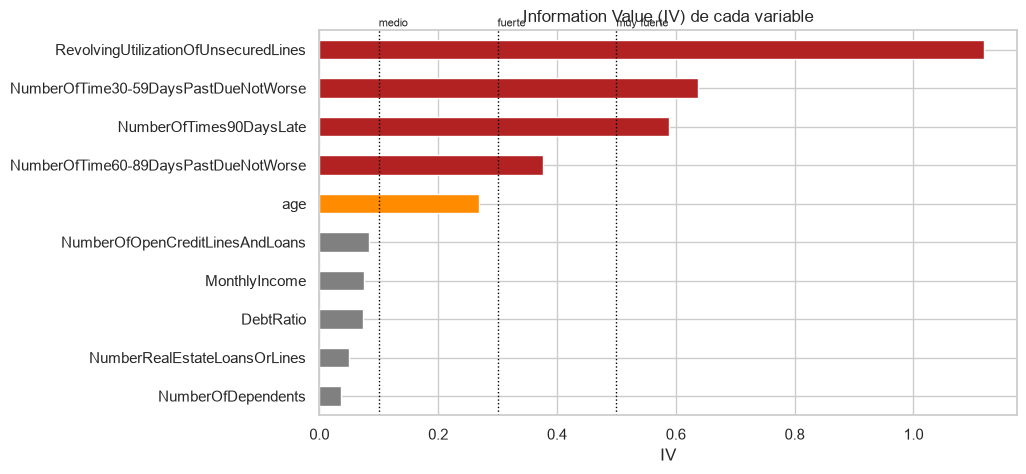

,IV
NumberOfDependents,0.036
NumberRealEstateLoansOrLines,0.049
DebtRatio,0.074
MonthlyIncome,0.076
NumberOfOpenCreditLinesAndLoans,0.083
age,0.269
NumberOfTime60-89DaysPastDueNotWorse,0.376
NumberOfTimes90DaysLate,0.588
NumberOfTime30-59DaysPastDueNotWorse,0.638
RevolvingUtilizationOfUnsecuredLines,1.118


In [35]:
def information_value(valores: pd.Series, objetivo: pd.Series, n_rangos: int = 10) -> float:
    """Calcula el Information Value de una variable cortada en cuantiles.

    Los valores faltantes forman un rango propio. Se suma 0.5 a cada conteo
    para evitar divisiones entre cero.

    Args:
        valores: Variable a evaluar.
        objetivo: Variable objetivo binaria (1 = moroso).
        n_rangos: Número de rangos por cuantiles.

    Returns:
        Information Value de la variable.
    """
    if valores.nunique() > n_rangos:
        rangos = pd.qcut(valores.rank(method="first"), n_rangos, labels=False)
    else:
        rangos = valores
    rangos = rangos.astype(float).fillna(-1)
    conteos = pd.crosstab(rangos, objetivo) + 0.5
    pct_morosos = conteos[1] / conteos[1].sum()
    pct_no_morosos = conteos[0] / conteos[0].sum()
    woe = np.log(pct_no_morosos / pct_morosos)
    return float(((pct_no_morosos - pct_morosos) * woe).sum())


datos_iv = train[FEATS].copy()
datos_iv[LATE] = datos_iv[LATE].where(datos_iv[LATE] < 96)  # 96/98 → rango propio
iv_variables = pd.Series(
    {col: information_value(datos_iv[col], train[TARGET]) for col in FEATS},
    name="IV",
).sort_values()

colores = ["firebrick" if v > 0.3 else "darkorange" if v > 0.1 else "gray"
           for v in iv_variables]
ax = iv_variables.plot(kind="barh", figsize=(9, 5), color=colores)
for umbral, texto in [(0.1, "medio"), (0.3, "fuerte"), (0.5, "muy fuerte")]:
    ax.axvline(umbral, color="black", ls=":", lw=1)
    ax.text(umbral, len(iv_variables) - 0.4, texto, fontsize=8)
ax.set_title("Information Value (IV) de cada variable")
ax.set_xlabel("IV")
plt.show()
iv_variables.round(3).to_frame()

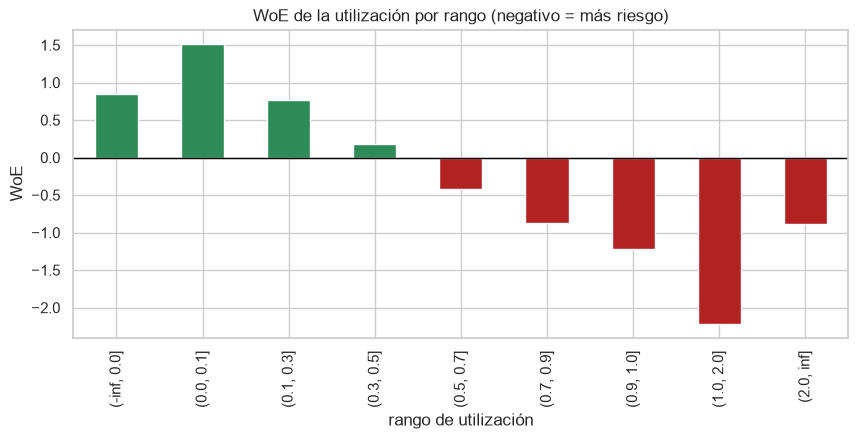

In [36]:
# WoE por rango de la utilización: así se ve la relación no lineal
rangos_util_woe = pd.cut(
    train["RevolvingUtilizationOfUnsecuredLines"],
    [-np.inf, 0, 0.1, 0.3, 0.5, 0.7, 0.9, 1, 2, np.inf],
)
conteos_util = pd.crosstab(rangos_util_woe, train[TARGET]) + 0.5
woe_util = np.log(
    (conteos_util[0] / conteos_util[0].sum()) / (conteos_util[1] / conteos_util[1].sum())
)
ax = woe_util.plot(kind="bar", figsize=(10, 4),
                   color=["firebrick" if w < 0 else "seagreen" for w in woe_util])
ax.axhline(0, color="black", lw=1)
ax.set_title("WoE de la utilización por rango (negativo = más riesgo)")
ax.set_xlabel("rango de utilización")
ax.set_ylabel("WoE")
plt.show()

**Lectura:**
- Cuatro variables concentran la señal: **utilización** y los **tres
  atrasos** (IV > 0.3). La edad tiene señal media. Ingreso, `DebtRatio`,
  líneas, hipotecas y dependientes son débiles por sí solas.
- El IV de la utilización (> 1) es muy alto. Aquí no es fuga de datos: el
  riesgo crece de forma muy marcada con la utilización, como vimos en la
  sección 10.4.
- El WoE muestra la **curva** que una regresión logística con la variable
  cruda no puede capturar. El riesgo sube hasta 1–2 (WoE −2.2) y cambia de
  tendencia después. También se dobla en el extremo bajo: utilización
  exactamente 0 (WoE 0.8) es menos segura que 0–0.1 (WoE 1.5). WoE convierte
  esa curva en una relación lineal.

**Ventajas para el modelo:**
- **Resuelve atípicos y faltantes:** el faltante se vuelve un rango más, con
  su propio WoE.
- **Capta relaciones no lineales.**
- **Da una selección de variables justificable** con el IV.
- **Es fácil de explicar.**

En el notebook 03 se recomienda `optbinning`, que busca cortes óptimos y
monótonos. Los cortes y el WoE se aprenden **dentro de cada pliegue**, porque
usan la variable objetivo.

#### b) Ingreso disponible (capacidad de pago)
`ingreso disponible = ingreso − monto mensual de deuda`: lo que le queda al
cliente después de pagar sus deudas.

,IV (clientes con ingreso > 0)
MonthlyIncome,0.088
DebtRatio,0.083
monto de deuda,0.035
ingreso disponible,0.161


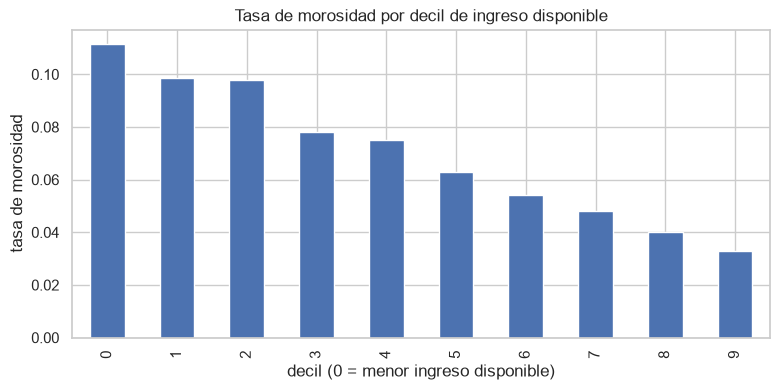

In [37]:
capacidad = train[train["MonthlyIncome"] > 0].copy()
capacidad["monto_deuda"] = capacidad["DebtRatio"] * capacidad["MonthlyIncome"]
capacidad["ingreso_disponible"] = capacidad["MonthlyIncome"] - capacidad["monto_deuda"]

iv_capacidad = pd.Series(
    {
        "MonthlyIncome": information_value(capacidad["MonthlyIncome"], capacidad[TARGET]),
        "DebtRatio": information_value(capacidad["DebtRatio"], capacidad[TARGET]),
        "monto de deuda": information_value(capacidad["monto_deuda"], capacidad[TARGET]),
        "ingreso disponible": information_value(
            capacidad["ingreso_disponible"], capacidad[TARGET]
        ),
    },
    name="IV (clientes con ingreso > 0)",
)
display(iv_capacidad.round(3).to_frame())

deciles_disp = pd.qcut(capacidad["ingreso_disponible"].rank(method="first"), 10, labels=False)
ax = capacidad.groupby(deciles_disp)[TARGET].mean().plot(kind="bar", figsize=(9, 4))
ax.set_title("Tasa de morosidad por decil de ingreso disponible")
ax.set_xlabel("decil (0 = menor ingreso disponible)")
ax.set_ylabel("tasa de morosidad")
plt.show()

**Lectura:** el ingreso disponible tiene un **IV de 0.161, casi el doble que
el ingreso solo (0.088)** y mucho más que el monto de deuda (0.035). Además, la
relación es **limpia y monótona**: la morosidad baja de 11.1 % en el decil con
menos ingreso disponible a 3.3 % en el de más. Es la variable nueva con más
señal de este análisis.

Para clientes sin ingreso no se puede calcular directamente: se usa el
ingreso imputado (⭐ A o 🔷 B) menos el monto de deuda, con el indicador
`income_missing`.

#### c) Imputación del ingreso con un modelo (estrategia C) y su trampa
En lugar de medianas, un modelo predice el ingreso con las demás
variables. Lo medimos con el mismo protocolo de la sección 10.3 d.

In [38]:
from sklearn.ensemble import HistGradientBoostingRegressor

vars_con_ratio = [c for c in FEATS if c != "MonthlyIncome"]
vars_con_monto = [c for c in vars_con_ratio if c != "DebtRatio"] + ["monto_deuda"]
error_modelos = {}
for nombre, columnas in [
    ("modelo con DebtRatio", vars_con_ratio),
    ("modelo con monto de deuda (sin DebtRatio)", vars_con_monto),
]:
    modelo = HistGradientBoostingRegressor(random_state=42)
    modelo.fit(ajuste[columnas], np.log1p(ajuste["MonthlyIncome"]))
    error_modelos[nombre] = float(np.abs(log_real - modelo.predict(prueba[columnas])).mean())

comparacion_c = pd.concat(
    [
        comparacion["error (MAE en log)"],
        pd.Series(error_modelos, name="error (MAE en log)"),
    ]
).to_frame()
comparacion_c["mejora vs global (%)"] = (
    1 - comparacion_c["error (MAE en log)"] / comparacion_c["error (MAE en log)"].iloc[0]
) * 100
comparacion_c.round(3)

,error (MAE en log),mejora vs global (%)
mediana global,0.577,0.000
mediana por grupo de edad,0.543,5.915
⭐ mediana por edad + n.º de créditos hipotecarios,0.515,10.611
mediana por decil del monto de deuda,0.498,13.678
mediana por edad + decil del monto de deuda,0.484,16.125
modelo con DebtRatio,0.363,37.099
modelo con monto de deuda (sin DebtRatio),0.474,17.861


**Lectura: la trampa.** El modelo con `DebtRatio` parece excelente (37.1 %
de mejora), pero **no sirve**:
- En los clientes **con** ingreso, `DebtRatio` es una razón (deuda /
  ingreso). Si el modelo también ve el resto del perfil, aprende a
  "despejar" el ingreso de esa razón.
- En los clientes **sin** ingreso, `DebtRatio` es un monto, no una razón. Esa
  relación no existe, y la predicción fallaría justo donde se necesita.

La versión correcta usa el monto de deuda, que significa lo mismo en ambos
grupos. Logra 17.9 %, apenas mejor que 🔷 B (16.1 %), y es más difícil de
explicar y de mantener. **No es prioritaria.**

#### d) Curvas suaves (*splines*) para la regresión logística
`SplineTransformer` de `scikit-learn` convierte una variable en varias
curvas suaves, para que la regresión logística capte relaciones no lineales
sin discretizar. Candidatas: **utilización** (sube y cambia de tendencia) y
**edad** (el riesgo baja de forma continua). Es la alternativa a WoE para
quien prefiera no agrupar en rangos.

#### e) Indicadores de perfil

In [39]:
sin_atrasos = train[LATE].where(train[LATE] < 96, 0).sum(axis=1) == 0
perfiles = {
    "utilización = 0": train["RevolvingUtilizationOfUnsecuredLines"] == 0,
    "expediente delgado (sin atrasos, sin utilización, ≤ 1 línea)": (
        sin_atrasos
        & (train["RevolvingUtilizationOfUnsecuredLines"] == 0)
        & (train["NumberOfOpenCreditLinesAndLoans"] <= 1)
    ),
}
pd.DataFrame(
    {
        "clientes": {k: int(m.sum()) for k, m in perfiles.items()},
        "tasa de morosidad": {k: train.loc[m, TARGET].mean() for k, m in perfiles.items()},
        "tasa del resto": {k: train.loc[~m, TARGET].mean() for k, m in perfiles.items()},
    }
).round(4)

,clientes,tasa de morosidad,tasa del resto
utilización = 0,7652,0.0297,0.0698
"expediente delgado (sin atrasos, sin utilización, ≤ 1 línea)",316,0.0158,0.0670


**Lectura:** quien no usa sus líneas de crédito tiene menos de la mitad del
riesgo promedio, y el expediente delgado todavía menos. Es el mismo tipo de
perfil que vimos en los registros con contenido repetido (sección 1). Son
indicadores baratos de construir y fáciles de interpretar.

#### Resumen de alternativas adicionales

| Alternativa | Evidencia | Recomendación |
| --- | --- | --- |
| **a) WoE / IV** | 4 variables con IV > 0.3; captura la curva de la utilización | ✅ **Prioridad alta:** enfoque paralelo para la regresión logística |
| **b) Ingreso disponible** | IV casi el doble que el del ingreso | ✅ **Prioridad alta:** variable nueva |
| c) Imputación con modelo | Con monto de deuda apenas mejora a 🔷 B | ❌ No prioritaria |
| d) *Splines* | Relaciones no lineales en utilización y edad | Experimento secundario |
| e) Indicadores de perfil | Utilización 0 y expediente delgado: menos de la mitad del riesgo | Experimento secundario (muy barato) |

### 10.9 Preparación del notebook de ingeniería de variables
Propuesta para `notebooks/03_ingenieria_variables` (el número `02` ya lo usa
`02_features_separabilidad` de Gustavo):

1. **Limpieza fija:** reutilizar `clean()` y `add_features()` de
   `src/features/features.py`, y agregar los recortes de la tabla 10.6 que
   aún no están (ingreso p99, líneas abiertas p99, hipotecas 5,
   dependientes 5).
2. **Imputador por grupos:** transformador de `scikit-learn` (con
   `fit`/`transform`) que aprende la mediana de cada grupo **solo con el
   pliegue de entrenamiento**, con respaldo a la mediana global. Va en
   `src/features/` con sus pruebas. Se usa tres veces:
   - ⭐ `income_imp_age_mortgage`: ingreso por edad + n.º de créditos
     hipotecarios.
   - 🔷 `income_imp_age_debt`: ingreso por edad + decil del monto mensual de
     deuda. Requiere antes la variable fija `debt_amount`
     (`DebtRatio × MonthlyIncome`, o `DebtRatio` si no hay ingreso); los
     cortes de los deciles también se aprenden en el pliegue.
   - `NumberOfDependents`: por edad.
3. **`ColumnTransformer`** con dos ramas: variables continuas
   (imputar → `log1p` → `StandardScaler`) e indicadores (sin cambio).
4. **Alternativas adicionales (sección 10.8):**
   - **WoE / IV** con `optbinning` como enfoque paralelo para la regresión
     logística (cortes y WoE aprendidos en cada pliegue).
   - **Ingreso disponible** (`ingreso − debt_amount`) como variable nueva,
     calculado con el ingreso imputado cuando falta.
   - Indicadores `util_zero` y `thin_file`; *splines* para utilización y
     edad.
5. **Experimentos** con validación cruzada estratificada de 5 pliegues,
   semilla 42 y AUC-ROC:
   - Ingreso: solo ⭐ A, solo 🔷 B, o **ambas variables** (con mediana
     global como línea base).
   - Escalado: `StandardScaler` contra `RobustScaler` contra
     `QuantileTransformer`.
   - Atrasos: conteo transformado contra binarizado.
   - Representación para la regresión logística: variables escaladas
     contra WoE contra *splines*.
   - Con y sin ingreso disponible e indicadores de perfil.
   - Modelos: regresión logística L1/L2 y un modelo de árboles.
6. **Cifras de control:** filas de entrada y salida, y cero `NaN` después de
   imputar.

El detalle queda en `docs/plan_ingenieria_variables.md`.

## 11. Resumen y siguientes pasos

| Hallazgo | Qué hacer después |
| --- | --- |
| Sin `Id` repetidos; 339 filas con mismo contenido y distinto `Id` | No se elimina nada; probar su efecto en validación cruzada |
| Perfiles idénticos con objetivo distinto | Se conservan; son ruido irreducible |
| Clase positiva muy minoritaria | Validación cruzada estratificada, AUC-ROC, `class_weight` |
| Faltantes en ingreso y dependientes (siempre juntos) | Ingreso: **dos variables imputadas**, ⭐ edad + hipotecas y 🔷 edad + decil de deuda; dependientes: mediana por edad; todas con indicador (sección 10.3) |
| Ingreso muy disperso (CV 2.3, máximo 120 veces el p99) | Recortar a p99 + `log1p` (sección 10.2) |
| `DebtRatio` es un monto cuando falta el ingreso (siempre está informado) | Separar en razón válida y monto de deuda; el monto ayuda a inferir el ingreso |
| PCA: el jugo en los datos se reparte en varios componentes | Ver sección 10.7 |
| Utilización y atrasos concentran la señal (IV > 0.3) | WoE / IV como enfoque paralelo (sección 10.8) |
| Ingreso disponible: IV casi el doble que el ingreso | Variable nueva (sección 10.8) |
| Códigos 96/98 en variables de atraso | Tratarlos aparte (NaN + indicador) |
| Edad 0, utilización y DebtRatio extremos | Recortar a percentil alto o limpiar |
| Variables muy asimétricas | Recortar → `log1p` → `StandardScaler` para modelos lineales; árboles sin escalado |
| Atrasos previos son los más predictivos | Crear variables agregadas de atrasos |

**Plan de experimentos sugerido:**
1. Línea base: regresión logística con regularización (L1/L2) sobre datos limpios y escalados.
2. Modelos de árboles: Random Forest y Gradient Boosting (manejan asimetría y no linealidad).
3. Validación cruzada estratificada de 5 particiones, medida en AUC-ROC.
4. Selección de hiperparámetros con búsqueda (`GridSearchCV` / `RandomizedSearchCV`).
5. Comparar el efecto de cada decisión de limpieza y de variables nuevas.

**Importante:** las transformaciones (medianas, escalado) se ajustan solo con
los datos de entrenamiento de cada partición, para evitar fuga de datos.